In [1]:
import json, glob, os, argparse, importlib, torch
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import cv2
import datetime
from matplotlib import pyplot as plt
import time
from PIL import Image
from torchvision.transforms import v2
from src.model.DamageQuantification import DamageQuantification
from src.dataset import standardize

/Data/home/tingyan/.conda/envs/hysteresis/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load regressor
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
regressor_path = "./results/DamageQuantification/vit_b_16/2024-06-12_14-01-03"
regressor_args = json.load(open(glob.glob(os.path.join(regressor_path, "**/args.json"), recursive=True)[0], "r"))
regressor_args = argparse.Namespace(**regressor_args)
regressor = importlib.import_module(f"src.model.DamageQuantification").__dict__["DamageQuantification"](**vars(regressor_args))
status = regressor.load_state_dict(torch.load(glob.glob(os.path.join(regressor_path, "**/r2*.ckpt"), recursive=True)[0])["state_dict"])
regressor = regressor.to(device)
print("Regressor Loading Status: ", status)

label = pd.read_csv("./Data/DamagePattern/label.csv")
info = pd.read_csv(os.path.join("./Data", "Hysteresis", f"info_w_mander_big.csv")).loc[:, regressor_args.column_info]
statistics = pd.read_csv(os.path.join("./Data", "Hysteresis", f"statistics_big.csv"), index_col=0)
info = standardize(info, statistics)

Regressor Loading Status:  <All keys matched successfully>


In [8]:
def predict_DI(path, label, regressor, info, device):
    custom_transform = v2.Compose([
        v2.Resize((224, 224)),
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    img = Image.open(path)
    img = custom_transform(img).unsqueeze(0).to(device)
    basename = path.split("/")[-1]
    exp = basename.split("_")[0]
    dir = basename.split("_")[1]
    drift = basename.split("_")[2]
    if len(basename.split("_")) == 4:
        cycle = basename.split("_")[3].split(".")[0]
    else:   
        cycle = basename.split("_")[3]
    

    filename = f"{exp}_{dir}_{drift}_{cycle}.jpg"
    
    features = info[info["id"] == exp].iloc[0, 1:].values
    features = features.astype(np.float32)
    features = torch.from_numpy(features).unsqueeze(0).to(device)
    gt_DI = label[label["filename"] == filename]["DI"].values
    with torch.no_grad():
        pred = regressor(img, features)
    pred = pred.cpu().numpy()
    pred_DI = pred[0][0]
    gt_DI = gt_DI[0]
    
    return pred_DI, gt_DI

def segmenation(path, n_clusters=2, kernel_size=11, image_size=None, linewidth=1):
    img = cv2.imread(path)
    # If image_size is not None, resize the image
    if image_size is not None:
        img = cv2.resize(img, image_size)
    # img = cv2.GaussianBlur(img, (9, 9), 0)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    reshape_img = img.reshape(img.shape[0] * img.shape[1], img.shape[2])
    
    kmeans = KMeans(n_clusters=n_clusters, n_init=40, max_iter=500).fit(reshape_img)
    clustering = np.reshape(np.array(kmeans.labels_, dtype=np.uint8),(img.shape[0], img.shape[1]))
    
    
    sortedLabels = sorted([n for n in range(n_clusters)], key=lambda x: -np.average(img_gray[clustering == x]))
    kmeansImage= np.zeros(img.shape[:2], dtype=np.uint8)
    for i, label in enumerate(sortedLabels):
        kmeansImage[clustering == label ] = int((255) / (n_clusters - 1)) * i

    plt.axis('off')
    plt.imshow(kmeansImage, cmap='gray')
    plt.show()

    # opening
    kmeansImage = cv2.morphologyEx(kmeansImage, cv2.MORPH_OPEN, np.ones((kernel_size,kernel_size),np.uint8))
    plt.axis('off')
    plt.imshow(kmeansImage, cmap='gray')
    plt.show()

    # # Add bottom border
    kmeansImage = cv2.copyMakeBorder(kmeansImage, 0, 1, 0, 0, cv2.BORDER_CONSTANT, value=255)


    # contour
    contours, _ = cv2.findContours(kmeansImage, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    vis_contours = cv2.drawContours(cv2.cvtColor(kmeansImage, cv2.COLOR_GRAY2RGB), contours, -1, (0, 255, 0), linewidth)

    
    return img , kmeansImage, contours

def find_max_contour_id(contours):
    max_contour_id = 0
    max_area = cv2.contourArea(contours[0])
    for i, contour in enumerate(contours):
        area = cv2.contourArea(contour)
        if area > max_area:
            max_area = area
            max_contour_id = i
    return max_contour_id

In [25]:
filename = "CTR1_SW_06000_5"
exp = filename.split("_")[0]
mode = "test"

In [29]:
from math import log10, sqrt 
def PSNR(original, compressed): 
    mse = np.mean((original - compressed) ** 2) 
    if(mse == 0):  # MSE is zero means no noise is present in the signal . 
                  # Therefore PSNR have no importance. 
        return 100
    max_pixel = 255.0
    psnr = 20 * log10(max_pixel / sqrt(mse)) 
    return psnr 

In [30]:
from skimage.metrics import structural_similarity as ssim
path1 = f"./Data/DamagePattern/images/{filename}.jpg"
path2 = f"./evaluation/RaSGAN_512_Latent/{exp}/{filename}_{mode}.jpg"
img1 = cv2.imread(path1)
img2 = cv2.imread(path2)
img1 = cv2.resize(img1, (512, 512))
ssim_score = ssim(img1, img2, channel_axis=2)
psnr = PSNR(img1, img2)

In [33]:
psnr

27.75033190341126

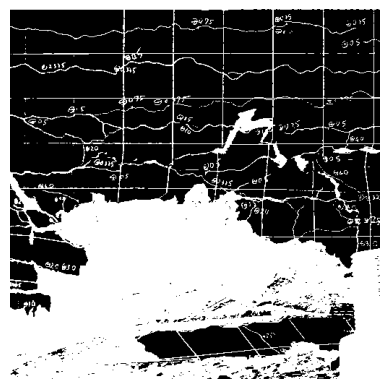

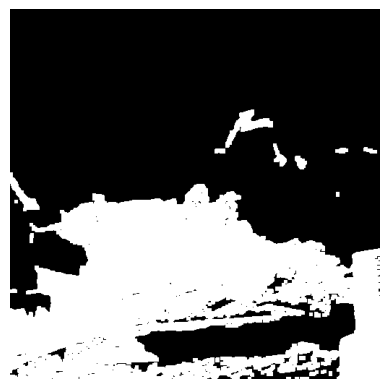

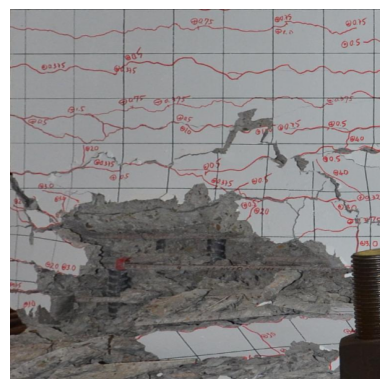

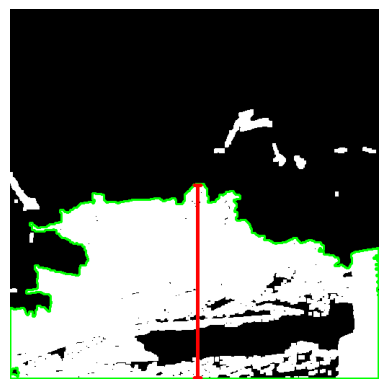

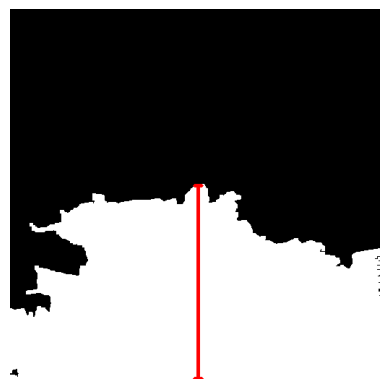

Height: 268 px( 41.88 cm)
Spalling Percentage: 40.01%
DI (pred): 1.0105
DI (gt): 0.9678


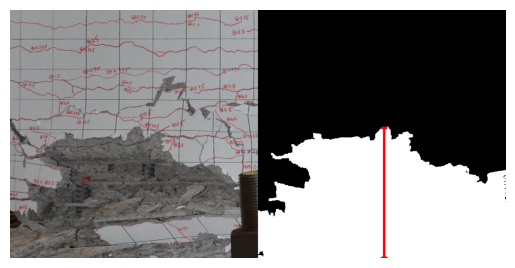

In [34]:
path = f"./Data/DamagePattern/images/{filename}.jpg"
# path = f"./evaluation/RaSGAN_512_Latent/{exp}/{filename}_{mode}.jpg"

pred_DI, gt_DI = predict_DI(path, label, regressor, info, device)
image_size = 512
img, kmeansImage, contours = segmenation(path, n_clusters=2, kernel_size=5, image_size=(image_size, image_size), linewidth=1)
max_contour_id = find_max_contour_id(contours)
max_contour = contours[max_contour_id]

img_pl = np.zeros((image_size, image_size), dtype=np.uint8)
cv2.drawContours(img_pl, contours, contourIdx=max_contour_id, color=255,thickness=-1)
img_pl_erode = cv2.erode(img_pl, np.ones((5,5),np.uint8), iterations=1)

# Calculate the percentage of the spalling area
spalling_percentage = img_pl.sum() / 255 / image_size / image_size * 100
spalling_y, spalling_x = np.where(img_pl_erode == 255)
y_id = np.argmin(spalling_y)
x = spalling_x[y_id]
y = spalling_y[y_id]
img_pl = cv2.cvtColor(img_pl, cv2.COLOR_GRAY2RGB)
cv2.line(img_pl, (x - 5, y), (x + 5, y), (0, 0, 255), 4)
cv2.line(img_pl, (x, y), (x, image_size), (0, 0, 255), 4)
cv2.line(img_pl, (x - 5, image_size-1), (x + 5, image_size-1), (0, 0, 255), 4)


plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

kmeansImage_contour = cv2.cvtColor(kmeansImage, cv2.COLOR_BGR2RGB)
cv2.drawContours(kmeansImage_contour, contours, contourIdx=max_contour_id, color=(0, 255, 0),thickness=2)
cv2.line(kmeansImage_contour, (x - 5, y), (x + 5, y), (255, 0, 0), 4)
cv2.line(kmeansImage_contour, (x, y), (x, image_size), (255, 0, 0), 4)
cv2.line(kmeansImage_contour, (x - 5, image_size-1), (x + 5, image_size-1), (255, 0, 0), 4)
plt.imshow(kmeansImage_contour)
plt.axis("off")
plt.show()

plt.imshow(cv2.cvtColor(img_pl, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


concatImage = np.concatenate((cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(img_pl, cv2.COLOR_BGR2RGB)), axis=1)
ymin = contours[-1].min(axis=1)
print(f"Height: {image_size - y} px({(image_size - y)/float(image_size)*80 : .2f} cm)")
print(f"Spalling Percentage: {spalling_percentage:.2f}%")
print(f"DI (pred): {pred_DI:.4f}")
print(f"DI (gt): {gt_DI:.4f}")
plt.imshow(concatImage)
plt.axis("off")
plt.show()

# Image.fromarray(concatImage).save(f"{filename}_{mode}_gt.jpg")

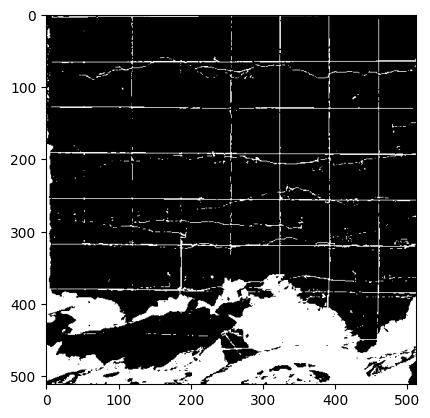

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 512 and the array at index 1 has size 513

In [9]:
path = f"./evaluation/RaSGAN_512_Latent/{exp}/{filename}_{mode}.jpg"
# path = "./R1015_SW_06000_2_val.jpg"
pred_DI, gt_DI = predict_DI(path, label, regressor, info, device)
image_size = 512
img, kmeansImage, contours = segmenation(path, n_clusters=2, kernel_size=1, image_size=(image_size, image_size), linewidth=1)
max_contour_id = find_max_contour_id(contours)
max_contour = contours[max_contour_id]

img_pl = kmeansImage
img_pl_erode = cv2.erode(kmeansImage, np.ones((3,3),np.uint8), iterations=1)
img_pl_erode = cv2.morphologyEx(img_pl_erode, cv2.MORPH_OPEN, np.ones((7,7),np.uint8))

# Calculate the percentage of the spalling area
spalling_percentage = img_pl_erode.sum() / 255 / image_size / image_size * 100
spalling_y, spalling_x = np.where(img_pl_erode == 255)
y_id = np.argmin(spalling_y)
x = spalling_x[y_id]
y = spalling_y[y_id]
img_pl_erode = cv2.cvtColor(img_pl_erode, cv2.COLOR_GRAY2RGB)
cv2.line(img_pl_erode, (x - 5, y), (x + 5, y), (0, 0, 255), 4)
cv2.line(img_pl_erode, (x, y), (x, image_size), (0, 0, 255), 4)
cv2.line(img_pl_erode, (x - 5, image_size-1), (x + 5, image_size-1), (0, 0, 255), 4)

concatImage = np.concatenate((cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(img_pl_erode, cv2.COLOR_BGR2RGB)), axis=1)
ymin = contours[-1].min(axis=1)
print(f"Height: {image_size - y} px({(image_size - y)/float(image_size)*80 : .2f} cm)")
print(f"Spalling Percentage: {spalling_percentage:.2f}%")
print(f"DI (pred): {pred_DI:.4f}")
print(f"DI (gt): {gt_DI:.4f}")
plt.imshow(concatImage)
plt.axis("off")
plt.show()

Image.fromarray(concatImage).save(f"{filename}_{mode}_512.jpg")

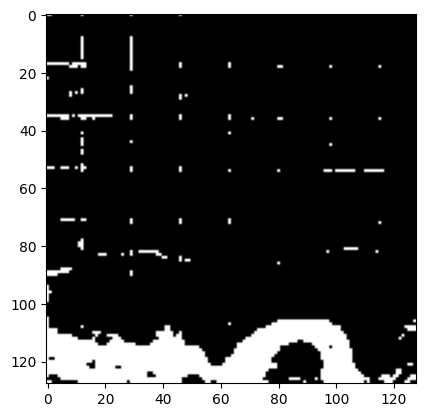

Height: 20 px( 12.50 cm)
Spalling Percentage: 10.75%
DI (pred): 0.4055
DI (gt): 0.5876


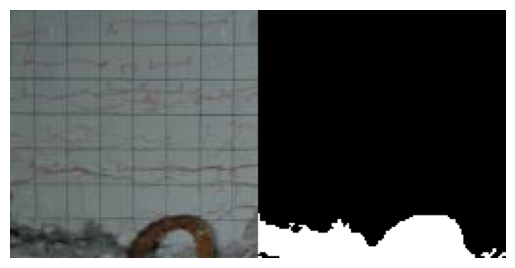

In [25]:
path = f"./evaluation/RaSGAN_128_Latent/{exp}/{filename}_{mode}.jpg"
pred_DI, gt_DI = predict_DI(path, label, regressor, info, device)
image_size = 128
img, kmeansImage, contours = segmenation(path, n_clusters=2, kernel_size=1, image_size=(image_size, image_size), linewidth=1)
max_contour_id = find_max_contour_id(contours)
max_contour = contours[max_contour_id]

img_pl = np.zeros((image_size, image_size), dtype=np.uint8)
cv2.drawContours(img_pl, contours, contourIdx=max_contour_id, color=255,thickness=-1)
img_pl_erode = cv2.erode(img_pl, np.ones((5,5),np.uint8), iterations=1)

# Calculate the percentage of the spalling area
spalling_percentage = img_pl.sum() / 255 / image_size / image_size * 100
spalling_y, spalling_x = np.where(img_pl_erode == 255)
y_id = np.argmin(spalling_y)
x = spalling_x[y_id]
y = spalling_y[y_id]
img_pl = cv2.cvtColor(img_pl, cv2.COLOR_GRAY2RGB)
# cv2.line(img_pl, (x - 3, y), (x + 3, y), (0, 0, 255), 1)
# cv2.line(img_pl, (x, y), (x, image_size), (0, 0, 255), 1)
# cv2.line(img_pl, (x - 3, image_size-1), (x + 3, image_size-1), (0, 0, 255), 1)

concatImage = np.concatenate((cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(img_pl, cv2.COLOR_BGR2RGB)), axis=1)
ymin = contours[-1].min(axis=1)
print(f"Height: {image_size - y} px({(image_size - y)/float(image_size)*80 : .2f} cm)")
print(f"Spalling Percentage: {spalling_percentage:.2f}%")
print(f"DI (pred): {pred_DI:.4f}")
print(f"DI (gt): {gt_DI:.4f}")
plt.imshow(concatImage)

plt.axis("off")
plt.show()

Image.fromarray(concatImage).save(f"{filename}_{mode}_128.jpg")

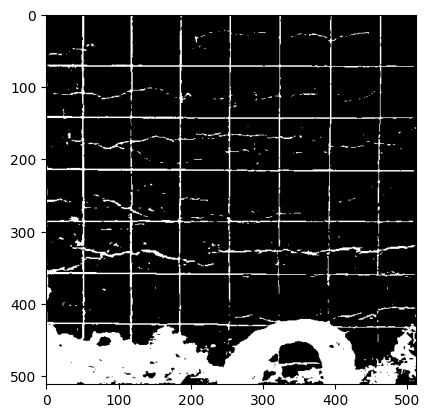

Height: 88 px( 13.75 cm)
Spalling Percentage: 11.32%
DI (pred): 0.6654
DI (gt): 0.5876


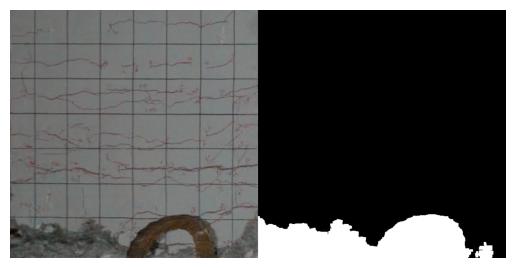

In [26]:
path = f"./evaluation/RaSGAN_512_Latent/{exp}/{filename}_{mode}.jpg"
pred_DI, gt_DI = predict_DI(path, label, regressor, info, device)
image_size = 512
img, kmeansImage, contours = segmenation(path, n_clusters=2, kernel_size=5, image_size=(image_size, image_size), linewidth=1)
max_contour_id = find_max_contour_id(contours)
max_contour = contours[max_contour_id]

img_pl = np.zeros((image_size, image_size), dtype=np.uint8)
cv2.drawContours(img_pl, contours, contourIdx=max_contour_id, color=255,thickness=-1)
img_pl_erode = cv2.erode(img_pl, np.ones((5, 5),np.uint8), iterations=1)

# Calculate the percentage of the spalling area
spalling_percentage = img_pl.sum() / 255 / image_size / image_size * 100
spalling_y, spalling_x = np.where(img_pl_erode == 255)
y_id = np.argmin(spalling_y)
x = spalling_x[y_id]
y = spalling_y[y_id]
img_pl = cv2.cvtColor(img_pl, cv2.COLOR_GRAY2RGB)
# cv2.line(img_pl, (x - 10, y), (x + 10, y), (0, 0, 255), 4)
# cv2.line(img_pl, (x, y), (x, image_size), (0, 0, 255), 4)
# cv2.line(img_pl, (x - 10, image_size-1), (x + 10, image_size-1), (0, 0, 255), 4)

concatImage = np.concatenate((cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(img_pl, cv2.COLOR_BGR2RGB)), axis=1)
ymin = contours[-1].min(axis=1)
print(f"Height: {image_size - y} px({(image_size - y)/float(image_size)*80 : .2f} cm)")
print(f"Spalling Percentage: {spalling_percentage:.2f}%")
print(f"DI (pred): {pred_DI:.4f}")
print(f"DI (gt): {gt_DI:.4f}")
plt.imshow(concatImage)
plt.axis("off")
plt.show()


Image.fromarray(concatImage).save(f"{filename}_{mode}_512.jpg")